# Bài thực hành 1 – Bài tập thêm 2: Dữ liệu môi trường nhà xưởng
Tiền xử lý dữ liệu `tb_tracking.xlsx`.

In [14]:
import numpy as np
import pandas as pd

import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt

Trang Kim Đạt 6451071018

## Đọc dữ liệu
File không có dòng tiêu đề nên dùng `header=None`.

In [15]:
df = pd.read_excel('tb_tracking.xlsx', header=None)
df.head(10)

,0,1,2,3,4,5
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01
5,6.0,100.0,2.0,3.0,400.0,2016-12-20 13:02:24
6,7.0,-1.0,0.0,83.0,28.0,2016-12-21 12:03:39
7,8.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:02
8,9.0,-1.0,0.0,83.0,28.0,2016-12-21 12:05:49
9,10.0,1.0,2.0,3.0,4.0,2016-12-21 12:08:58


Trang Kim Đạt 6451071018

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 33340 entries, 0 to 33339
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   0       33339 non-null  float64       
 1   1       33339 non-null  float64       
 2   2       33339 non-null  float64       
 3   3       33339 non-null  float64       
 4   4       33339 non-null  float64       
 5   5       33339 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(5)
memory usage: 1.5 MB


Cuối file có 1 dòng trống và 3 dòng thống kê (min, max, trung bình) không phải dữ liệu đo.
Ta cắt bỏ từ dòng trống đầu tiên trở xuống.

In [18]:
df.tail(6)

,0,1,2,3,4,5
33334,33335.0,0.000000,32.000000,61.000000,2.096030e+06,2018-01-17 15:41:29.000
33335,33336.0,0.000000,31.500000,62.000000,2.004240e+06,2018-01-17 15:46:34.000
33336,NaN,NaN,NaN,NaN,NaN,NaT
33337,1.0,-1.000000,0.000000,0.000000,0.000000e+00,2016-12-20 12:52:29.000
33338,33336.0,99005.000000,4030.000000,11030.000000,5.340310e+06,2018-01-17 15:46:34.000
33339,16668.5,97931.172516,181.704089,2127.562065,1.384405e+05,2017-03-15 06:51:12.688


Trang Kim Đạt 6451071018

In [19]:
blank_rows = df[df.isnull().all(axis=1)].index
if len(blank_rows) > 0:
    df = df.loc[:blank_rows[0] - 1]
df.tail()

,0,1,2,3,4,5
33331,33332.0,0.0,32.0,58.0,2049770.0,2018-01-17 15:26:12
33332,33333.0,0.0,32.0,58.0,1983470.0,2018-01-17 15:31:18
33333,33334.0,0.0,32.0,59.0,2119740.0,2018-01-17 15:36:24
33334,33335.0,0.0,32.0,61.0,2096030.0,2018-01-17 15:41:29
33335,33336.0,0.0,31.5,62.0,2004240.0,2018-01-17 15:46:34


Trang Kim Đạt 6451071018

## a) Thêm tiêu đề cho các cột

In [20]:
df.columns = ['id', 'device_id', 'co_level', 'humidity', 'temperature', 'time']

# id và device_id là mã định danh nên chuyển về số nguyên
df['id'] = df['id'].astype(int)
df['device_id'] = df['device_id'].astype(int)
df['time'] = pd.to_datetime(df['time'])
df.head()

,id,device_id,co_level,humidity,temperature,time
0,1,1,2.0,3.0,4.0,2016-12-20 12:52:29
1,2,1,2.0,3.0,4.0,2016-12-20 12:52:31
2,3,100,2.0,3.0,4.0,2016-12-20 12:52:35
3,4,100,2.0,3.0,400.0,2016-12-20 12:52:37
4,5,1,2.0,3.0,4.0,2016-12-20 13:02:01


Trang Kim Đạt 6451071018

In [21]:
df.describe()

,id,device_id,co_level,humidity,temperature,time
count,33336.000000,33336.000000,33336.000000,33336.000000,3.333600e+04,33336
mean,16668.500000,97931.172516,181.704089,2127.562065,1.384405e+05,2017-03-15 06:51:12.688054
min,1.000000,-1.000000,0.000000,0.000000,0.000000e+00,2016-12-20 12:52:29
25%,8334.750000,99001.000000,33.000000,32.000000,1.000000e+01,2017-01-06 07:56:17.500000
50%,16668.500000,99005.000000,43.000000,54.000000,8.700000e+01,2017-03-11 12:59:16.500000
75%,25002.250000,99005.000000,76.000000,92.000000,1.099600e+04,2017-04-25 07:13:55.500000
max,33336.000000,99005.000000,4030.000000,11030.000000,5.340310e+06,2018-01-17 15:46:34
std,9623.418623,10245.683485,710.038650,4301.534982,5.612185e+05,NaN


Trang Kim Đạt 6451071018

## b) Chỉ giữ dữ liệu đo từ ngày 03/01/2018 trở đi

In [22]:
print('Trước khi lọc:', len(df), 'dòng')
df = df[df['time'] >= '2018-01-03'].reset_index(drop=True)
print('Sau khi lọc :', len(df), 'dòng')
print('Từ', df['time'].min(), 'đến', df['time'].max())

Trước khi lọc: 33336 dòng
Sau khi lọc : 1917 dòng
Từ 2018-01-03 13:11:07 đến 2018-01-17 15:46:34


Trang Kim Đạt 6451071018

## c) Tách thời điểm đo trong ngày tính theo phút (minutes)

In [23]:
df['minutes'] = df['time'].dt.hour * 60 + df['time'].dt.minute
df[['time', 'minutes']].head(10)

,time,minutes
0,2018-01-03 13:11:07,791
1,2018-01-03 13:15:10,795
2,2018-01-03 13:17:30,797
3,2018-01-03 13:19:21,799
4,2018-01-03 13:24:17,804
5,2018-01-03 13:29:13,809
6,2018-01-03 13:34:10,814
7,2018-01-03 14:05:34,845
8,2018-01-03 14:10:43,850
9,2018-01-03 14:15:39,855


Trang Kim Đạt 6451071018

In [24]:
df['minutes'].describe()

count    1917.000000
mean      709.297861
std       391.934697
min         1.000000
25%       396.000000
50%       713.000000
75%       993.000000
max      1439.000000
Name: minutes, dtype: float64

Trang Kim Đạt 6451071018

## d) Đồ thị phân tán nồng độ CO, độ ẩm và nhiệt độ theo minutes

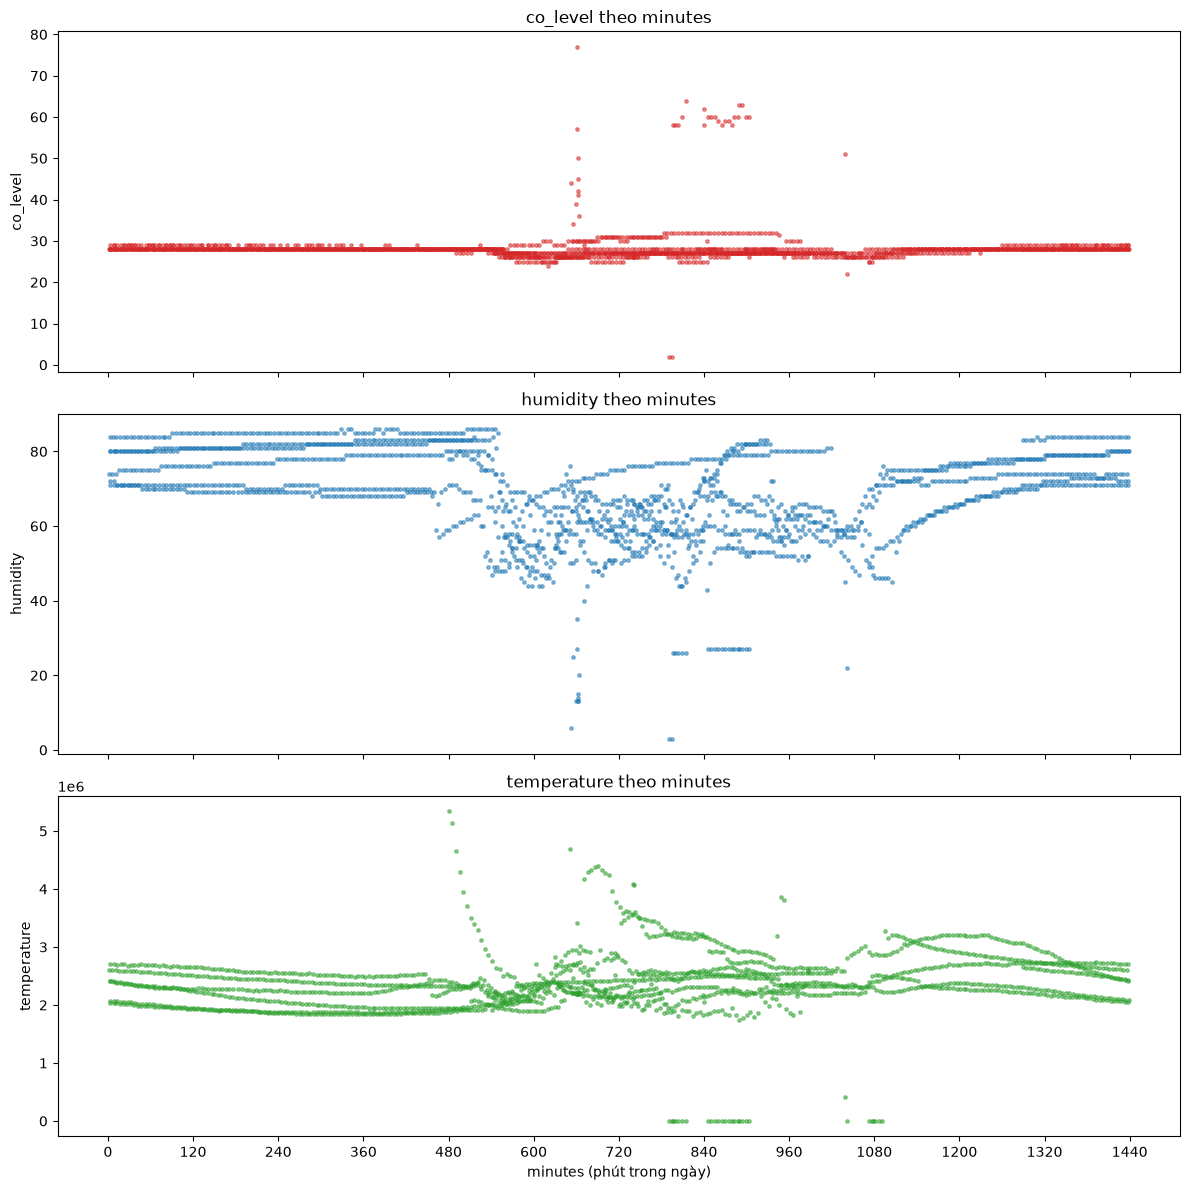

In [25]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(12, 12), sharex=True)
for ax, col, color in zip(axes, ['co_level', 'humidity', 'temperature'], ['tab:red', 'tab:blue', 'tab:green']):
    ax.scatter(df['minutes'], df[col], s=6, alpha=0.5, color=color)
    ax.set_ylabel(col)
    ax.set_title(col + ' theo minutes')
axes[-1].set_xlabel('minutes (phút trong ngày)')
axes[-1].set_xticks(range(0, 1441, 120))
plt.tight_layout()
plt.show()

Trang Kim Đạt 6451071018

Có thể vẽ riêng từng biểu đồ bằng seaborn:

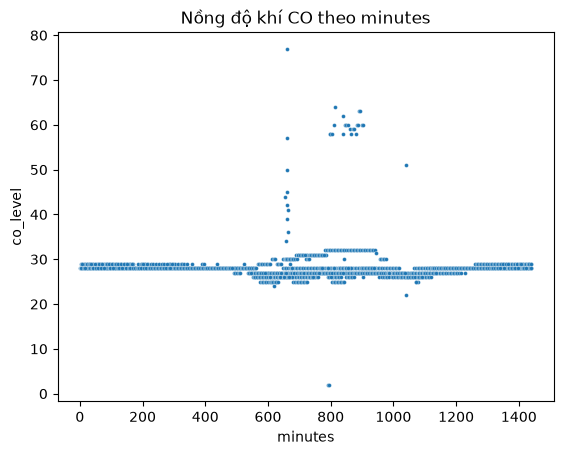

In [26]:
sns.scatterplot(x='minutes', y='co_level', data=df, s=8)
plt.title('Nồng độ khí CO theo minutes')
plt.show()

Trang Kim Đạt 6451071018

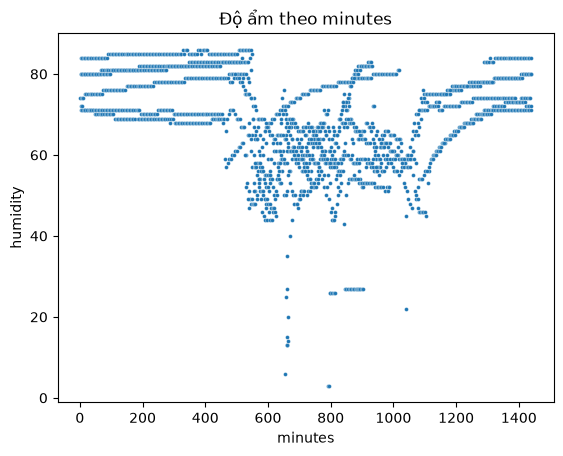

In [27]:
sns.scatterplot(x='minutes', y='humidity', data=df, s=8)
plt.title('Độ ẩm theo minutes')
plt.show()

Trang Kim Đạt 6451071018

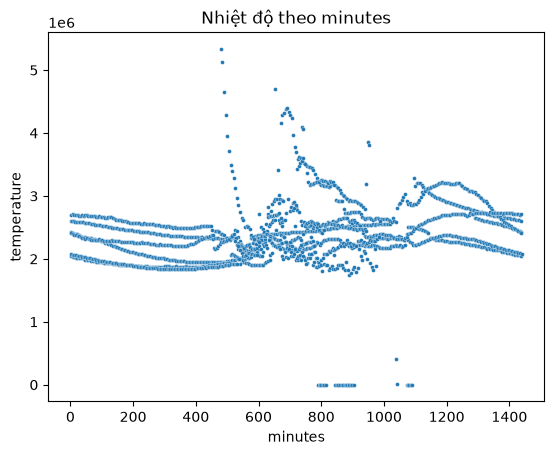

In [28]:
sns.scatterplot(x='minutes', y='temperature', data=df, s=8)
plt.title('Nhiệt độ theo minutes')
plt.show()

Trang Kim Đạt 6451071018